# MVP second run: adding the state of the economy

Notebook 03 fit two supervised models on respondent attributes alone. This notebook adds the state of the economy and
the presidency at the time of each interview, as two blocks that enter separately and together, and adds a third model,
a penalised logit. It covers, in order: how the state variables were chosen and dated, the four feature sets, the
penalised logit, how the scores are broken down by period and party, and the results.

Everything not described here is unchanged from notebook 03: the cleaning, the encoding of respondent attributes, the
training and evaluation windows, the two scores, their reference points and the bootstrap. Results are read from
`experiments/mvp/2026-10-26-supervised-macro-politics-ridge/`, written by
`python -m sdt.mvp.run supervised-macro-politics-ridge`.

In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sdt.mvp import encode
from sdt.mvp.clean import CLASSES, FIRST_MONTH, INPUTS, OUT_PATH, OUTCOMES, load_raw
from sdt.mvp.models import Ridge, mnl
from sdt.mvp.run import EXPERIMENTS, FEATURE_SETS
from sdt.mvp.score import GROUPS, PERIODS, cells, item_data
from sdt.mvp.state import MACRO, POLITICS, PRESIDENT, WINNER, build, load
from sdt.mvp.windows import TRAIN_END, split
from sdt.paths import DATA
pd.set_option('display.max_columns', None); pd.set_option('display.width', None)
ITEMS = list(OUTCOMES)
SHORT = {'demographics': 'D', 'demographics_macro': 'D+M', 'demographics_politics': 'D+P', 'demographics_macro_politics': 'D+M+P'}
month = lambda m: pd.to_datetime(pd.Series(m).astype(str), format='%Y%m')

clean = pd.read_parquet(OUT_PATH)
train, test = split(clean)
state = build(sorted(clean.YYYYMM.unique())).set_index('YYYYMM')
RUN = EXPERIMENTS / '2026-10-26-supervised-macro-politics-ridge'
scores = pd.read_csv(RUN / 'scores.csv')
pred = pd.read_parquet(RUN / 'predictions.parquet')
ridge_settings = json.load(open(RUN / 'ridge_settings.json'))
meta = json.load(open(RUN / 'run.json'))
print(f"Run of {meta['date']} at commit {meta['commit'][:7]}, data.csv SHA-256 {meta['data_csv_sha256'][:12]}...")

Run of 2026-10-26 at commit 53877d8, data.csv SHA-256 5e0a7e1cd2a0...


## 1. State variables

### 1.1 Choosing them

The state variables follow from a rule rather than from a list of plausible indicators, so that no choice depends on
which variables would help:

1. **Candidate questions.** The 15 main questions asked in every survey month from January 1978 to February 2026. Coded
   reasons and the sub-steps of a question do not count as separate questions.
2. **Named concept.** Each question's wording names what it asks about. Only concepts about the whole economy count: a
   question about the respondent's own finances does not, and "is now a good time to buy" names no quantity.
3. **Measure.** Each concept gets the headline measure of the agency that publishes it. Government is measured by the
   party of the president, the head of the executive.

In [2]:
CORE = {  # question: (gist of the codebook wording, concept named)
    'PAGO':  ('better or worse off financially than a year ago', 'own finances'),
    'PEXP':  ('better or worse off a year from now', 'own finances'),
    'RINC':  ('will your income go up more than prices', 'own income; prices'),
    'BAGO':  ('business conditions better or worse than a year ago', 'business conditions'),
    'BEXP':  ('business conditions better or worse a year from now', 'business conditions'),
    'BUS12': ('good or bad times for business in the next 12 months', 'business conditions'),
    'BUS5':  ('good times or widespread unemployment in the next 5 years', 'business conditions; unemployment'),
    'NEWS1': ('news heard of changes in business conditions', 'business conditions'),
    'UNEMP': ('more or less unemployment in the next 12 months', 'unemployment'),
    'GOVT':  ("government's steps to fight inflation or unemployment", 'government; prices; unemployment'),
    'RATEX': ('interest rates for borrowing money in the next 12 months', 'interest rates'),
    'PX1':   ('prices in general in the next 12 months', 'prices'),
    'DUR':   ('good or bad time to buy major household items', 'none'),
    'HOM':   ('good or bad time to buy a house', 'none'),
    'CAR':   ('good or bad time to buy a vehicle', 'none'),
}
q = pd.read_csv(DATA / 'data.csv', skipinitialspace=True, usecols=['YYYYMM'] + list(CORE))
asked = q[list(CORE)].notna().groupby(q.YYYYMM).mean().gt(0.5).sum()
pd.DataFrame({'wording': [w for w, _ in CORE.values()], 'concept named': [c for _, c in CORE.values()],
              'months asked': [f'{asked[k]} of {q.YYYYMM.nunique()}' for k in CORE]}, index=pd.Index(CORE, name='question'))

,wording,concept named,months asked
question,,,
PAGO,better or worse off financially than a year ago,own finances,578 of 578
PEXP,better or worse off a year from now,own finances,578 of 578
RINC,will your income go up more than prices,own income; prices,578 of 578
BAGO,business conditions better or worse than a yea...,business conditions,578 of 578
BEXP,business conditions better or worse a year fro...,business conditions,578 of 578
BUS12,good or bad times for business in the next 12 ...,business conditions,578 of 578
BUS5,good times or widespread unemployment in the n...,business conditions; unemployment,578 of 578
NEWS1,news heard of changes in business conditions,business conditions,578 of 578
UNEMP,more or less unemployment in the next 12 months,unemployment,578 of 578


Five concepts are named. Their measures:

| Concept | Measure | Agency | Why this series |
|---|---|---|---|
| Prices | CPI-U, all items, % change over 12 months | BLS | The headline inflation rate, computed from the index before seasonal adjustment |
| Unemployment | Unemployment rate, seasonally adjusted | BLS | The headline rate of the monthly jobs report |
| Business conditions | Real GDP, % change over 4 quarters | BEA | The official measure of the national economy |
| Interest rates | Effective federal funds rate | Federal Reserve | The one rate set by policy; consumer borrowing rates are many and privately published |
| Government | Party of the sitting president; party of the most recent election winner | | The two differ between the election and the inauguration |

Each economic measure enters twice: its latest value, and its change from a year earlier. The questions ask about
change ("better or worse than a year ago", "in the next 12 months"), and a model that sees only a level cannot tell
rising unemployment from falling unemployment. That makes 8 macro variables (`cpi`, `unrate`, `gdp` and `effr`, each
with a `_d1y` change) and 2 political ones (`pres_R`, `winner_R`). A real interest rate is not added: it is the federal
funds rate minus inflation, which a linear model can already form from the two.

### 1.2 Dating them

The survey records only the survey month of an interview, and a month's interviews run over a window of about four
weeks that starts late in the previous calendar month. Every variable takes the value that was public at the end of the
day before the window opened, as it was published then. Statistics are revised after their first release, so today's
value is often not what anyone could see at the time. ALFRED, FRED's archive of past releases, keeps every published
version of a series with the dates it was current. Real GDP for the third quarter of 2024 has had five:

In [3]:
g = load('GDPC1')
g[g.date == '2024-07-01'].assign(realtime_end=lambda d: d.realtime_end.replace('9999-12-31', 'still current'))[
    ['date', 'value', 'realtime_start', 'realtime_end']].style.hide(axis='index').format(
    {'value': '{:,.1f}', 'date': '{:%Y-%m-%d}', 'realtime_start': '{:%Y-%m-%d}'})

date,value,realtime_start,realtime_end
2024-07-01,"23,386.2",2024-10-30,2024-11-26
2024-07-01,"23,386.7",2024-11-27,2024-12-18
2024-07-01,"23,400.3",2024-12-19,2025-09-24
2024-07-01,"23,478.6",2025-09-25,2026-09-29
2024-07-01,"23,501.8",2026-09-30,still current


A window that opened on 21 January 2025 gets 23,400.3, the value current on 20 January. For each survey month and
series:

1. The cutoff is the day before the interview window opens.
2. Keep the published values released on or before the cutoff.
3. Keep one version per observation: the latest released.
4. Drop observations that were never published.
5. The latest remaining observation gives the current value.
6. Values a year earlier come from the same published versions.

Values are rounded to the precision the agency publishes (0.1, or 0.01 for the federal funds rate), and changes are
computed from the rounded values. The window dates come from Michigan's release calendar
(`data/external/sca/interview_windows.csv`), whose November 2020 start date is an error in the source; it is set to
27 October, the day after the October window closed.

December 2025 shows the edge cases. Its window opened on 18 November 2025, after the federal shutdown had delayed or
cancelled several releases:

In [4]:
m = 202512
rows = {}
for series, var in [('CPIAUCNS', 'cpi'), ('UNRATE', 'unrate'), ('GDPC1', 'gdp'), ('DFF', 'effr')]:
    first = load(series).dropna(subset=['value']).groupby('date').realtime_start.min()
    used = state.loc[m, f'{var}_obs']
    later = first[first.index > used]
    rows[var] = {'observation used': f'{used:%Y-%m-%d}', 'published': f'{first[used]:%Y-%m-%d}',
                 'next observation': f'{later.index[0]:%Y-%m-%d}', 'next published': f'{later.iloc[0]:%Y-%m-%d}',
                 'value': state.loc[m, var], 'change from a year earlier': state.loc[m, f'{var}_d1y']}
print(f"December 2025 window: cutoff {state.loc[m, 'cutoff']:%Y-%m-%d}")
pd.DataFrame(rows).T

December 2025 window: cutoff 2025-11-17


,observation used,published,next observation,next published,value,change from a year earlier
cpi,2025-09-01,2025-10-24,2025-11-01,2025-12-18,3.0,0.6
unrate,2025-08-01,2025-09-05,2025-09-01,2025-11-20,4.3,0.1
gdp,2025-04-01,2025-07-30,2025-07-01,2025-12-23,2.1,-1.0
effr,2025-11-14,2025-11-17,2025-11-15,2025-11-18,3.88,-0.7


September CPI was published late, on 24 October. October CPI was never published, so the next observation is
November's, released on 18 December. September unemployment came out on 20 November, three days after the cutoff, so
the window still gets August's rate. GDP is the most out of date: the third quarter of 2025 was not published until
23 December.

### 1.3 The presidency

`pres_R` is 1 when the sitting president is a Republican. `winner_R` is 1 when the most recent presidential election
was won by a Republican, counted from the day the Associated Press called the race. Both follow the same cutoff as the
data: an event dated on or before the cutoff counts.

In [5]:
cal = pd.DataFrame([(d, 'inauguration', 'pres_R', p) for d, p in PRESIDENT] + [(d, 'AP call', 'winner_R', p) for d, p in WINNER],
                   columns=['date', 'event', 'variable', 'party']).sort_values('date').set_index('date')
differ = state.loc[state.pres_R != state.winner_R, ['cutoff', 'pres_R', 'winner_R']]
display(cal, differ.assign(sample=np.where(differ.index <= TRAIN_END, 'training', 'evaluation')))

,event,variable,party
date,,,
2016-11-09,AP call,winner_R,R
2017-01-20,inauguration,pres_R,R
2020-11-07,AP call,winner_R,D
2021-01-20,inauguration,pres_R,D
2024-11-06,AP call,winner_R,R
2025-01-20,inauguration,pres_R,R


,cutoff,pres_R,winner_R,sample
YYYYMM,,,,
202012,2020-11-22,1,0,training
202101,2021-01-01,1,0,training
202412,2024-11-18,0,1,evaluation
202501,2024-12-16,0,1,evaluation


The two variables differ in four survey months, two in training and two in evaluation, with the parties reversed. What
a model learns about a party that has won the election but not yet taken office rests on December 2020 and January 2021.
Figure 1 shows all 10 variables by month.

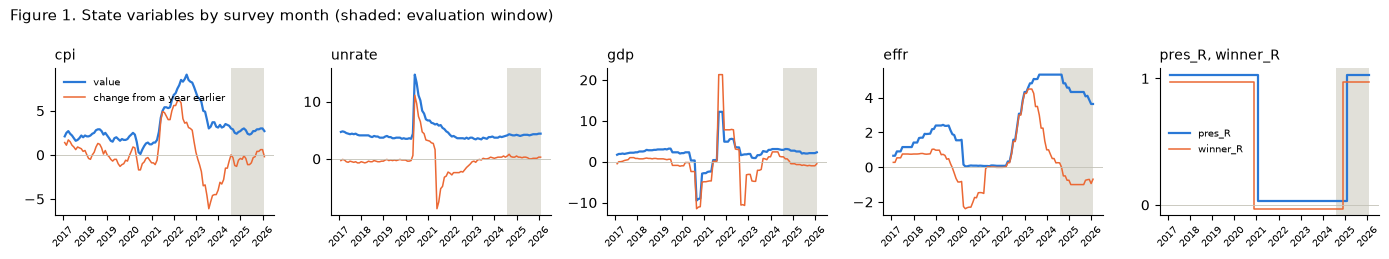

,cpi,cpi_d1y,unrate,unrate_d1y,gdp,gdp_d1y,effr,effr_d1y
training min,0.1,-6.1,3.4,-8.7,-9.5,-11.5,0.05,-2.39
training max,9.1,6.2,14.7,11.1,12.2,21.3,5.33,4.50
evaluation min,2.3,-1.3,4.0,0.0,2.0,-1.0,3.64,-1.00
evaluation max,3.0,0.6,4.4,0.8,3.1,1.2,5.33,0.25


In [6]:
x = month(state.index)
fig, axes = plt.subplots(1, 5, figsize=(14, 2.6))
for ax, v in zip(axes, ['cpi', 'unrate', 'gdp', 'effr']):
    ax.plot(x, state[v].values, color='#2a78d6', lw=1.6, label='value')
    ax.plot(x, state[f'{v}_d1y'].values, color='#eb6834', lw=1.1, label='change from a year earlier')
    ax.set_title(v, loc='left', fontsize=10)
ax = axes[4]
ax.step(x, state.pres_R.values + 0.03, where='post', color='#2a78d6', lw=1.6, label='pres_R')
ax.step(x, state.winner_R.values - 0.03, where='post', color='#eb6834', lw=1.1, label='winner_R')
ax.set_title('pres_R, winner_R', loc='left', fontsize=10); ax.set_yticks([0, 1])
for ax in axes:
    ax.axvspan(month([TRAIN_END + 1]).iloc[0], x.iloc[-1], color='#e1e0d9', lw=0)
    ax.axhline(0, color='#c3c2b7', lw=0.6); ax.tick_params(axis='x', labelsize=7, rotation=45)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].legend(frameon=False, fontsize=7.5, loc='upper left'); axes[4].legend(frameon=False, fontsize=7.5, loc='center left')
fig.suptitle('Figure 1. State variables by survey month (shaded: evaluation window)', x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()
tr, ev = state.loc[:TRAIN_END, MACRO], state.loc[TRAIN_END + 1:, MACRO]
pd.DataFrame({'training min': tr.min(), 'training max': tr.max(), 'evaluation min': ev.min(), 'evaluation max': ev.max()}).T

Every evaluation value lies inside the range seen in training, mostly near its middle. The training range is wide
because of a few episodes: the COVID recession of 2020, the inflation of 2021 to 2023 and the rate rises that followed.
Each variable takes one value per survey month, so although training has 55,867 interviews, it has only 90 values of
each state variable, and only one change of president. Whatever the models learn about the effect of the state, they
learn from how answers moved across those 90 months.

## 2. Four feature sets

A first run put all 10 state variables into one set and fit only the two models of notebook 03
(`experiments/mvp/2026-10-26-supervised-demographics-state/`). Its logit improved the individual score on four of five
items but predicted the monthly answer shares worse than the baseline shares, so this run enters the two blocks
separately and together, to see which block causes what, and adds the penalised logit of section 3. Its two models are
refit here and give identical predictions.

| Feature set | Short name | Adds to the respondent attributes |
|---|---|---|
| `demographics` | D | nothing (notebook 03) |
| `demographics_macro` | D+M | the 8 macro variables |
| `demographics_politics` | D+P | the 2 political variables |
| `demographics_macro_politics` | D+M+P | all 10 |

In the logit, the state variables enter linearly, and the political block also adds respondent party times each
president variable: `POLAFF=Rep:pres_R`, `POLAFF=Dem:pres_R`, `POLAFF=Rep:winner_R` and `POLAFF=Dem:winner_R`. In the
training months, party on its own explains under 1% of the variance of any answer, while party times presidency explains
22% for the government-policy question and about 11% for business conditions (notebook 01): Republicans and Democrats
trade places when the White House changes hands. A linear logit can move the two parties in opposite directions only
through such products. Each product measures alignment with the president, which only a respondent who states a party
can have, so independents and non-reporters share the reference response.

The five interviews of notebook 03 gain these columns in the logit on D+M+P, joined by survey month:

In [7]:
raw = load_raw()
raw = raw[raw.YYYYMM >= FIRST_MONTH].set_index('CASEID')
cases = {
    'phone, complete': (raw.METHOD == 1) & raw[INPUTS].notna().all(axis=1) & (raw[list(OUTCOMES)] < 8).all(axis=1),
    'web, blank demographics, party NA': (raw.METHOD == 2) & raw.AGE.isna() & raw.SEX.isna() & (raw.POLAFF == 9),
    'web, adults in household coded 9': (raw.METHOD == 2) & (raw.NUMADT == 9) & raw.POLAFF.isin([1, 2]),
    'phone, "with qualifications" and DK': (raw.BUS12 == 2) & (raw.PEXP == 8),
    'phone, lowest education code': (raw.BUS5 == 4) & (raw.EDUC == 1),
}
ids = [raw[m].sample(1, random_state=0).index[0] for m in cases.values()]
c = clean.set_index('CASEID').loc[ids]
X = encode.mnl_demographics_macro_politics_features(c)
new = [k for k in X if k not in encode.mnl_features(c)]
pd.concat([c[['YYYYMM', 'POLAFF']], X[new]], axis=1).style.format(precision=2, na_rep='NaN').format(
    precision=0, subset=['YYYYMM'] + POLITICS + [k for k in new if ':' in k])

,YYYYMM,POLAFF,cpi,cpi_d1y,unrate,unrate_d1y,gdp,gdp_d1y,effr,effr_d1y,pres_R,winner_R,POLAFF=Rep:pres_R,POLAFF=Dem:pres_R,POLAFF=Rep:winner_R,POLAFF=Dem:winner_R
CASEID,,,,,,,,,,,,,,,,
296239,202104,Rep,1.70,-0.60,6.20,2.70,-2.40,-4.70,0.07,-0.08,0,0,0,0,0,0
321940,202408,NaN,3.00,0.00,4.10,0.50,2.90,1.20,5.33,0.25,0,0,0,0,0,0
341248,202602,Dem,2.70,-0.20,4.40,0.30,2.30,-0.50,3.64,-0.69,1,1,0,1,0,1
265873,201702,Rep,2.10,1.40,4.70,-0.30,1.70,-0.50,0.66,0.28,1,1,1,0,1,0
288836,202004,Ind,2.30,0.80,3.50,-0.30,2.30,-0.20,0.15,-2.26,1,1,0,0,0,0


Boosting gets the same 10 variables without products, since its trees can split on party within a presidency
themselves:

In [8]:
G = encode.gb_demographics_macro_politics_features(c)
new = [k for k in G if k not in encode.gb_features(c)]
pd.concat([c[['YYYYMM', 'POLAFF']], G[new]], axis=1).style.format(precision=2, na_rep='NaN').format(
    precision=0, subset=['YYYYMM'] + POLITICS)

,YYYYMM,POLAFF,cpi,cpi_d1y,unrate,unrate_d1y,gdp,gdp_d1y,effr,effr_d1y,pres_R,winner_R
CASEID,,,,,,,,,,,,
296239,202104,Rep,1.70,-0.60,6.20,2.70,-2.40,-4.70,0.07,-0.08,0,0
321940,202408,NaN,3.00,0.00,4.10,0.50,2.90,1.20,5.33,0.25,0,0
341248,202602,Dem,2.70,-0.20,4.40,0.30,2.30,-0.50,3.64,-0.69,1,1
265873,201702,Rep,2.10,1.40,4.70,-0.30,1.70,-0.50,0.66,0.28,1,1
288836,202004,Ind,2.30,0.80,3.50,-0.30,2.30,-0.20,0.15,-2.26,1,1


## 3. A penalised logit

A state variable takes one value per month, so every interview in a month shares it, along with whatever else moved
answers that month. The logit of notebook 03 counts each interview as independent evidence, so on D+M+P it fits 28
coefficients on 14 month-level columns from what is really 90 months of variation, and can fit month-to-month noise.
A standard remedy is a penalised logit, known as ridge, which shrinks coefficients toward zero, trading some fit to the
training data for estimates that vary less. Two features of this setup could limit what it achieves. The likelihood in
its loss still counts each interview as independent, so the penalty treats state coefficients as just as well
determined as any other. And cross-validation holds out months from within the training window, so it favours
coefficients that fit between training months even if they fail after.

Ridge differs from the logit of notebook 03 in two ways:

1. **Standardised inputs.** Each column is rescaled to weighted mean 0 and weighted standard deviation (SD) 1:
   z = (x − mean) / SD. For `cpi`, whose training mean is about 3.46 and SD about 2.26, August 2024's 3.0 becomes
   −0.20. The penalty compares the sizes of coefficients, which are comparable across columns only in common units;
   after rescaling, each coefficient is the effect of a one-SD change in its column on the log-odds. The mean does not
   affect predictions, since the intercept absorbs it, and the SD is weighted so that it describes households, as the
   weighted likelihood does.
2. **A penalised loss.** Instead of the weighted negative log-likelihood, ridge minimises
   C × (weighted negative log-likelihood) + ½ × (sum of squared coefficients), with the intercepts left out of the sum.
   A coefficient grows only while a further increase improves C × the log-likelihood by more than it adds to the
   penalty. A smaller C means a stronger penalty, and C = ∞ is the logit of notebook 03.

C is chosen from 14 values, 10⁻⁴ to 10² in half-decade steps and ∞, separately for each item and feature set:

1. Encode the training interviews that answered the item with the feature set's logit columns (section 2).
2. Split the training months into the five folds that tune boosting (notebook 03, section 3.2).
3. For each fold and each value of C, standardise the other four folds' interviews, fit, rescale the held-out fold with
   the same mean and SD, and score its weighted log loss.
4. Choose the C with the lowest loss averaged over the five folds.
5. Standardise all training interviews and refit with that C.
6. To predict, rescale evaluation interviews with the training mean and SD.

| | |
|---|---|
| **Form** | P(y = c \| z) = exp(α_c + β_c · z) / Σ_k exp(α_k + β_k · z), for c and k in fav, mid, unf, with the α_c and the β_c each summing to zero across the three answers instead of α_fav = 0 and β_fav = 0 |
| **Inputs** | The logit's 39 to 53 columns of each feature set (section 2), standardised as above |
| **Parameters** | 80 to 108 per item: an intercept and 39 to 53 coefficients for each of fav, mid and unf, summing to zero across them |
| **Estimation** | Weighted maximum likelihood with weights `WT` and the ridge penalty: `StandardScaler` and `LogisticRegression(C)`, both with weights `WT`, lbfgs solver, tolerance 1e-8, up to 10,000 iterations; every item and feature set converged, in 38 to 233 |
| **Tuning** | C per item and feature set, from the 14 values above, by the month-blocked folds of notebook 03, section 3.2 |
| **Other settings** | scikit-learn 1.9.1 defaults |

The chosen values of C:

In [9]:
grid = lambda r: {('none' if g['C'] is None else g['C']): g['val_log_loss'] for g in r['grid']}
chosen, iters, rows = {}, [], []
for fs, d in ridge_settings.items():
    chosen[SHORT[fs]] = {item: f"{r['chosen_C']:.0e}" if r['chosen_C'] else 'none' for item, r in d.items()}
    for item, r in d.items():
        X, y, w = item_data(train, item, FEATURE_SETS[fs]['mnl'])
        iters.append(Ridge(np.inf if r['chosen_C'] is None else r['chosen_C']).fit(X, y, sample_weight=w).logit_.n_iter_.max())
        rows.append(len(X))
print(f'Training interviews per item: {min(rows):,} to {max(rows):,}; final fits converged in {min(iters)} to {max(iters)} iterations')
pd.DataFrame(chosen).loc[ITEMS].join(
    pd.Series({item: max(grid(d[item])['none'] - min(grid(d[item]).values()) for d in ridge_settings.values())
               for item in ITEMS}, name='largest validation gain over no penalty').map('{:.4f}'.format))

Training interviews per item: 52,209 to 55,814; final fits converged in 38 to 233 iterations


,D,D+M,D+P,D+M+P,largest validation gain over no penalty
PAGO,1e-02,3e-02,1e-02,3e-02,0.0001
PEXP,3e-03,3e-02,3e-02,3e-02,0.0001
BUS12,3e-03,1e-01,3e-03,1e-01,0.0002
BUS5,3e-03,3e-03,1e-02,1e-02,0.0002
DUR,3e-03,3e-02,3e-03,3e-02,0.0006


Every item and feature set chose C between 0.003 and 0.1, and the gain over no penalty on held-out months is at most
0.0006 in log loss. What the chosen penalty does to the coefficients of the `DUR` logit on D+M+P, and what a much
stronger one would do, on the standardised scale (favourable versus unfavourable):

In [10]:
X, y, w = item_data(train, 'DUR', encode.mnl_demographics_macro_politics_features)
coef = lambda m: pd.Series(m.logit_.coef_[list(m.classes_).index('fav')] - m.logit_.coef_[list(m.classes_).index('unf')], index=X.columns)
C = ridge_settings['demographics_macro_politics']['DUR']['chosen_C']
plain, ridge, strong = (coef(Ridge(c).fit(X, y, sample_weight=w)) for c in [np.inf, C, 1e-4])
cols = ['POLAFF=Rep', 'web', 'cpi', 'cpi_d1y', 'effr', 'pres_R', 'winner_R', 'POLAFF=Rep:pres_R']
Z = (X - np.average(X, axis=0, weights=w)) / np.sqrt(np.average((X - np.average(X, axis=0, weights=w)) ** 2, axis=0, weights=w))
A = np.column_stack([np.ones(len(Z)), Z.drop(columns='pres_R')]) * np.sqrt(w.to_numpy())[:, None]
resid = Z.pres_R * np.sqrt(w) - A @ np.linalg.lstsq(A, Z.pres_R * np.sqrt(w), rcond=None)[0]
print(f"{(ridge / plain >= 0.9).sum()} of {len(plain)} coefficients keep 90% or more at the chosen C; "
      f"the other columns explain {1 - (resid ** 2).sum() / (Z.pres_R ** 2 * w).sum():.0%} of the variation in pres_R")
pd.DataFrame({'unpenalised': plain[cols], f'ridge, C = {C:.2g}': ridge[cols], 'share kept': ridge[cols] / plain[cols],
              'ridge, C = 1e-4': strong[cols], 'share kept at 1e-4': strong[cols] / plain[cols]}).T.round(3)

49 of 53 coefficients keep 90% or more at the chosen C; the other columns explain 97% of the variation in pres_R


,POLAFF=Rep,web,cpi,cpi_d1y,effr,pres_R,winner_R,POLAFF=Rep:pres_R
unpenalised,-0.119,-0.139,-1.030,0.628,0.166,-0.036,0.259,0.247
"ridge, C = 0.032",-0.118,-0.133,-0.996,0.592,0.149,-0.010,0.248,0.230
share kept,0.991,0.960,0.967,0.943,0.901,0.269,0.955,0.932
"ridge, C = 1e-4",-0.060,-0.061,-0.236,-0.019,-0.027,0.202,0.213,0.113
share kept at 1e-4,0.504,0.438,0.229,-0.030,-0.163,-5.690,0.823,0.457


At the chosen C, 49 of the 53 coefficients keep 90% or more. `pres_R` keeps 27%: the other columns explain 97% of its
variation, because `winner_R` and the macro variables change in the same months, so the likelihood loses little when
it shrinks. At C = 10⁻⁴, `cpi` keeps about a quarter of its coefficient and `POLAFF=Rep` half, and some correlated
state coefficients change sign as the penalty moves their shared signal from one to another.

## 4. Scoring by period and party

The two scores of notebook 03 are also computed in 16 cells: each period, and all months, crossed with each party and
all respondents. Each period starts with the first interview window that contains its event:

- **Baseline**, August to October 2024: the same regime as the end of training.
- **Flip**, November 2024 to January 2025: from the election, whose result reverses the partisan pattern.
- **Tariffs**, February 2025 to February 2026: from the first tariff orders on 1 February.

The periods matter because the state changes most at the election and with the tariffs, and a pooled score is
dominated by the 13 tariff months. The parties matter because Republicans and Democrats moved in opposite directions
after the election, which cancels in the answer shares of all respondents. Non-reporters count only in "all".

In [11]:
pd.DataFrame({(p, g): {'interviews': len(d), 'months': d.YYYYMM.nunique()} for p, g, d in cells(clean)}).T.unstack().astype(int)

interviews                    months            
                Dem   Ind   Rep    all    Dem Ind Rep all
Baseline        976   955   761   3067      3   3   3   3
Flip            859   871   682   2711      3   3   3   3
Tariffs        5473  5123  3250  15405     13  13  13  13
all            7308  6949  4693  21183     19  19  19  19

The cell of all months and all respondents reproduces notebook 03's scores exactly. Each model's skill against the
baseline shares comes with a 95% paired-bootstrap interval, as do these differences: each larger feature set minus D
within each model family, and ridge minus logit and logit minus boosting within each feature set. The Flip period has
three months, and the intervals count only respondent sampling, not which months occurred, so they
understate uncertainty most there.

## 5. Results

### 5.1 Individual score

Skill against the baseline shares (1 − log loss / baseline log loss), over all evaluation months. Models are named by
family (`mnl` the logit, `ridge`, `gb` boosting) and feature set:

In [12]:
allc = scores[(scores.period == 'all') & (scores.group == 'all')]
def table(s, fams=('mnl', 'ridge', 'gb'), sets=tuple(SHORT), score='log_loss_skill', d=allc):
    t = d.set_index(['model', 'item'])[score]
    return pd.DataFrame({item: {f'{f} {SHORT[fs]}': t[(f'{f}_{fs}', item)] for f in fams for fs in sets} for item in ITEMS})
table(allc).style.format('{:+.1%}').background_gradient(cmap='RdBu', vmin=-0.1, vmax=0.1)

,PAGO,PEXP,BUS12,BUS5,DUR
mnl D,+2.2%,-1.8%,-0.0%,+1.7%,+0.7%
mnl D+M,+1.5%,-3.6%,-0.9%,-0.9%,-1.0%
mnl D+P,-0.6%,-6.1%,-6.0%,+2.9%,-22.2%
mnl D+M+P,+4.1%,-1.4%,+4.3%,+2.7%,-4.0%
ridge D,+2.2%,-1.8%,+0.6%,+2.3%,+0.5%
ridge D+M,+1.5%,-3.6%,-1.0%,+0.2%,-1.0%
ridge D+P,-0.6%,-6.2%,-4.1%,+3.1%,-22.0%
ridge D+M+P,+4.0%,-1.6%,+4.4%,+3.8%,-4.3%
gb D,-2.2%,-5.2%,-13.6%,-4.9%,-1.5%
gb D+M,-3.4%,-6.7%,-3.7%,-2.4%,-27.0%


D+M+P improves the logit's individual score over D on four items, most on `BUS12` (from 0.0% to +4.3%), and worsens
it on `DUR`, where no model beats the logit on D. D+P worsens it on four items, `DUR` by 23 points. Ridge is within 2
points of the logit everywhere. Boosting is below or level with the logit everywhere except `BUS12` on D+P, where it
has the best score of any model.

What each block adds to the logit, by period (log loss of the larger set minus that of D; negative is better):

In [13]:
pm = lambda r, k=3: f"{r.log_loss:+.{k}f} [{r.log_loss_lo:+.{k}f}, {r.log_loss_hi:+.{k}f}]"
rows = {}
for fs in ['demographics_macro', 'demographics_politics', 'demographics_macro_politics']:
    for p in ['all', *PERIODS]:
        d = scores[(scores.model == f'mnl_{fs}-mnl_demographics') & (scores.period == p) & (scores.group == 'all')].set_index('item')
        rows[(SHORT[fs] + ' − D', p)] = d.loc[ITEMS].apply(pm, axis=1)
pd.DataFrame(rows).T

item                                   PAGO                     PEXP  \
D+M − D   all       +0.007 [+0.006, +0.009]  +0.019 [+0.017, +0.021]   
          Baseline  +0.008 [+0.002, +0.013]  +0.000 [-0.005, +0.006]   
          Flip      -0.004 [-0.009, +0.000]  -0.001 [-0.006, +0.004]   
          Tariffs   +0.009 [+0.007, +0.011]  +0.026 [+0.025, +0.028]   
D+P − D   all       +0.030 [+0.025, +0.036]  +0.048 [+0.042, +0.054]   
          Baseline  -0.041 [-0.048, -0.033]  -0.017 [-0.025, -0.008]   
          Flip      -0.020 [-0.031, -0.009]  -0.009 [-0.020, +0.000]   
          Tariffs   +0.053 [+0.045, +0.060]  +0.071 [+0.063, +0.079]   
D+M+P − D all       -0.020 [-0.024, -0.017]  -0.005 [-0.010, -0.000]   
          Baseline  -0.034 [-0.043, -0.026]  -0.018 [-0.027, -0.009]   
          Flip      -0.026 [-0.038, -0.016]  -0.010 [-0.021, -0.000]   
          Tariffs   -0.017 [-0.021, -0.013]  -0.002 [-0.008, +0.004]   

item                                  BUS12                     BUS5  \
D+M − D   all       +0.010 [+0.008, +0.011]  +0.028 [+0.027, +0.029]   
          Baseline  +0.004 [-0.003, +0.011]  -0.004 [-0.007, -0.001]   
          Flip      -0.004 [-0.007, -0.000]  +0.006 [+0.003, +0.009]   
          Tariffs   +0.013 [+0.012, +0.014]  +0.038 [+0.037, +0.040]   
D+P − D   all       +0.063 [+0.057, +0.069]  -0.012 [-0.016, -0.008]   
          Baseline  -0.068 [-0.078, -0.057]  -0.041 [-0.050, -0.032]   
          Flip      +0.015 [+0.002, +0.028]  -0.032 [-0.041, -0.023]   
          Tariffs   +0.098 [+0.090, +0.106]  -0.003 [-0.008, +0.002]   
D+M+P − D all       -0.046 [-0.051, -0.042]  -0.010 [-0.014, -0.007]   
          Baseline  -0.066 [-0.079, -0.053]  -0.045 [-0.054, -0.035]   
          Flip      +0.003 [-0.009, +0.014]  -0.020 [-0.029, -0.012]   
          Tariffs   -0.051 [-0.056, -0.046]  -0.002 [-0.006, +0.002]   

item                                    DUR  
D+M − D   all       +0.012 [+0.009, +0.014]  
          Baseline  +0.030 [+0.020, +0.040]  
          Flip      -0.021 [-0.028, -0.013]  
          Tariffs   +0.014 [+0.012, +0.016]  
D+P − D   all       +0.163 [+0.154, +0.172]  
          Baseline  -0.018 [-0.021, -0.014]  
          Flip      -0.020 [-0.034, -0.004]  
          Tariffs   +0.231 [+0.219, +0.243]  
D+M+P − D all       +0.033 [+0.029, +0.038]  
          Baseline  -0.003 [-0.011, +0.006]  
          Flip      -0.027 [-0.038, -0.016]  
          Tariffs   +0.051 [+0.045, +0.057]

The political block helps in Baseline on every item and in Flip on `PAGO`, `BUS5` and `DUR`, then hurts in Tariffs on
four items, on `DUR` by 0.23. The macro block hurts on every item in Tariffs and is mixed before. Yet in Tariffs the
two blocks together help on `PAGO` and `BUS12`, where each alone hurts. Section 5.3 shows why.

### 5.2 Distributional score

Skill against the baseline shares (1 − Wasserstein distance / baseline Wasserstein distance), over all evaluation
months:

In [14]:
table(allc, score='wasserstein_skill').style.format('{:+.0%}').background_gradient(cmap='RdBu', vmin=-1, vmax=1)

,PAGO,PEXP,BUS12,BUS5,DUR
mnl D,+2%,-3%,+1%,+1%,-1%
mnl D+M,-91%,-27%,-10%,-11%,-71%
mnl D+P,-290%,-97%,-67%,-22%,-406%
mnl D+M+P,-101%,-58%,-7%,-17%,-174%
ridge D,+1%,-4%,+1%,+3%,-1%
ridge D+M,-91%,-27%,-10%,-6%,-70%
ridge D+P,-289%,-97%,-67%,-23%,-400%
ridge D+M+P,-107%,-61%,-6%,-14%,-181%
gb D,-21%,-11%,-6%,+0%,-3%
gb D+M,-343%,-66%,-8%,+0%,-500%


Every model with a state block predicts the monthly answer shares worse than the baseline shares, on every item
but one where it ties, often with more than double the baseline's distance. Boosting's distance is larger than the
logit's for 10 of the 15 combinations of item and feature set with a state block. The logit and ridge on D stay
within 4 points of zero. Figure 2 shows why for two items: the favourable share predicted by the logit
with each feature set, by month.

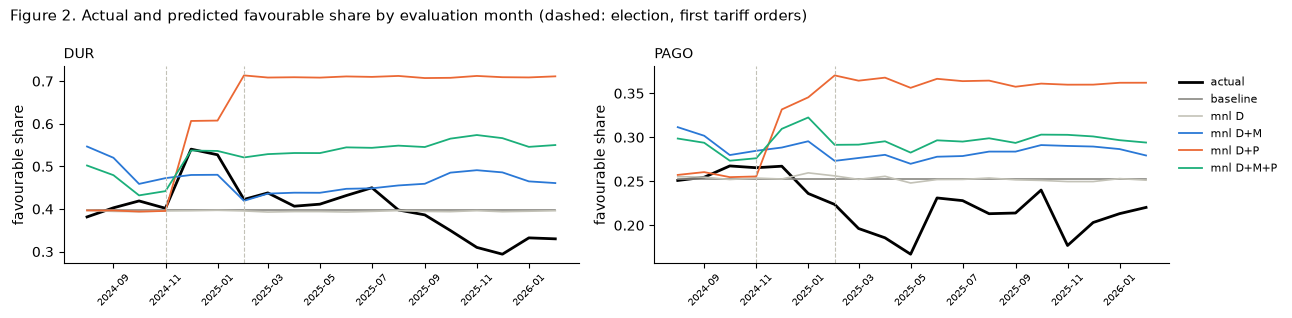

In [15]:
key = clean.set_index('CASEID')
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2))
for ax, item in zip(axes, ['DUR', 'PAGO']):
    for model, color, lw in [('actual', 'black', 2), ('baseline', '#898781', 1.2), ('mnl_demographics', '#c3c2b7', 1.2),
                             ('mnl_demographics_macro', '#2a78d6', 1.3), ('mnl_demographics_politics', '#eb6834', 1.3),
                             ('mnl_demographics_macro_politics', '#1baf7a', 1.3)]:
        g = pred[(pred.model == ('baseline' if model == 'actual' else model)) & (pred.item == item)]
        a = key.loc[g.CASEID]
        fav = (a[item] == 'fav').to_numpy(float) if model == 'actual' else g.fav.to_numpy()
        s = pd.Series(fav * a.WT.to_numpy()).groupby(a.YYYYMM.to_numpy()).sum() / a.WT.groupby(a.YYYYMM.to_numpy()).sum()
        ax.plot(month(s.index), s.values, color=color, lw=lw, label=model.replace('mnl_demographics', 'mnl D').replace('_macro', '+M').replace('_politics', '+P'))
    for d in ['2024-11-01', '2025-02-01']:
        ax.axvline(pd.Timestamp(d), color='#c3c2b7', lw=0.8, ls='--')
    ax.set_title(item, loc='left', fontsize=10); ax.set_ylabel('favourable share'); ax.tick_params(axis='x', labelsize=7, rotation=45)
    ax.spines[['top', 'right']].set_visible(False)
axes[1].legend(frameon=False, fontsize=8, loc='upper left', bbox_to_anchor=(1, 1))
fig.suptitle('Figure 2. Actual and predicted favourable share by evaluation month (dashed: election, first tariff orders)',
             x=0.01, ha='left', fontsize=10.5)
plt.tight_layout(); plt.show()

The two blocks fail in different ways. D+M (blue) is off from the first evaluation month. D+P (orange) is close until
December 2024 and then jumps: from February 2025 it predicts that 71% of respondents think it a good time to buy major
household items (`DUR`), against an actual 29% to 45%. D+M+P (green) sits between the two.

### 5.3 Why the blocks fail

**The political block learns eras, not presidents.** Training contains one Republican presidency, 2017 to January 2021,
and one Democratic one, February 2021 to July 2024, and `pres_R` cannot tell the president apart from everything else
that differed between those two periods:

In [16]:
ph = train[train.web == 0]
era = lambda d, item: np.average(d[item] == 'fav', weights=d.WT)
pd.DataFrame({item: {'Feb 2017 to Jan 2021 (Republican president)': era(ph[(ph.YYYYMM <= 202101) & ph[item].notna()], item),
                     'Feb 2021 to Jun 2024 (Democratic president)': era(ph[(ph.YYYYMM > 202101) & ph[item].notna()], item)}
              for item in ITEMS}).style.format('{:.0%}').set_caption('Favourable share, telephone interviews in training')

,PAGO,PEXP,BUS12,BUS5,DUR
Feb 2017 to Jan 2021 (Republican president),49%,41%,51%,46%,74%
Feb 2021 to Jun 2024 (Democratic president),35%,32%,33%,35%,44%


Under the first president, 74% of telephone respondents said it was a good time to buy major household items; under
the second, with high inflation and rising rates, 44% did. On D+P, the logit attributes that whole
difference to the party of the president, so from February 2025 it predicts the answers of the first Trump years for
everyone. On D+M+P, part of the difference is attributed to inflation and rates instead, which is why D+M+P sits
between the two in Figure 2. The party products themselves work: the favourable share of `BUS12` by party, actual and
predicted by the logit:

In [17]:
ev = key.loc[pred[(pred.item == 'BUS12') & (pred.model == 'baseline')].CASEID]
period = pd.Series(np.array(list(PERIODS))[np.searchsorted(list(PERIODS.values()), ev.YYYYMM, side='right') - 1], index=ev.index)
rows = {}
for party in ['Rep', 'Dem']:
    for p in PERIODS:
        e = ev[(ev.POLAFF == party) & (period == p)]
        r = {'actual': np.average(e.BUS12 == 'fav', weights=e.WT)}
        for fs in ['demographics', 'demographics_politics', 'demographics_macro_politics']:
            g = pred[(pred.item == 'BUS12') & (pred.model == f'mnl_{fs}')].set_index('CASEID').loc[e.index]
            r[f'mnl {SHORT[fs]}'] = np.average(g.fav, weights=e.WT)
        rows[(party, p)] = r
pd.DataFrame(rows).T.style.format('{:.0%}')

On D, the logit predicts the same partisan gap in every period. On D+P, Republicans move from 9% to 32% and then 40%
favourable, close to the actual 10%, 40% and 43%, and Democrats move the other way. The partisan
reversal of the election is learned from its one precedent in training. What fails is the level shared by everyone.

**The macro block turns small moves into level shifts.** For `DUR`, the logit on D+M+P predicts a favourable share
of 43% for the July 2024 web interviews, the last month of training, and 50% for August, against an
actual 38%. The state variables barely moved between the two windows, but the fitted coefficients turn the small moves
into a 7-point shift:

In [18]:
X, y, w = item_data(train, 'DUR', encode.mnl_demographics_macro_politics_features)
fit = mnl().fit(X, y, sample_weight=w)
coef = pd.Series(fit.coef_[list(fit.classes_).index('fav')] - fit.coef_[list(fit.classes_).index('unf')], index=X.columns)
move = state.loc[202408, MACRO] - state.loc[202407, MACRO]
share = lambda rows: np.average(fit.predict_proba(X.loc[rows])[:, list(fit.classes_).index('fav')], weights=w.loc[rows])
Xa, ya, wa = item_data(test[test.YYYYMM == 202408], 'DUR', encode.mnl_demographics_macro_politics_features)
jul = X.index[(train.loc[X.index, 'YYYYMM'] == 202407).to_numpy()]
print(f"DUR favourable share, logit D+M+P: July 2024 web, predicted {share(jul):.0%}; August 2024 predicted "
      f"{np.average(fit.predict_proba(Xa)[:, list(fit.classes_).index('fav')], weights=wa):.0%}, actual {np.average(ya == 'fav', weights=wa):.0%}")
pd.DataFrame({'July 2024': state.loc[202407, MACRO], 'August 2024': state.loc[202408, MACRO], 'change': move,
              'coefficient (fav vs unf)': coef[MACRO], 'contribution to log-odds': coef[MACRO] * move}).astype(float).round(3).T

DUR favourable share, logit D+M+P: July 2024 web, predicted 43%; August 2024 predicted 50%, actual 38%


,cpi,cpi_d1y,unrate,unrate_d1y,gdp,gdp_d1y,effr,effr_d1y
July 2024,3.300,-0.700,4.000,0.300,2.90,1.200,5.330,0.260
August 2024,3.000,0.000,4.100,0.500,2.90,1.200,5.330,0.250
change,-0.300,0.700,0.100,0.200,0.00,0.000,0.000,-0.010
coefficient (fav vs unf),-0.456,0.237,-0.114,0.015,0.02,-0.012,0.089,0.234
contribution to log-odds,0.137,0.166,-0.011,0.003,0.00,-0.000,0.000,-0.002


Inflation fell 0.3 points, and its change from a year earlier rose 0.7 points because inflation a year earlier had
fallen faster. With the fitted coefficients, those two moves add about 0.3 to the log-odds of "good time to buy", which
takes the predicted share from 43% to 50%. The coefficients are fitted to 90 months dominated by a few episodes, and
nothing in training checks whether they hold in new months.

### 5.4 Ridge

Ridge minus logit, all months, log loss:

In [19]:
d = allc[allc.model.str.match(r'ridge_.*-mnl_')].assign(set=lambda d: d.model.str.extract(r'ridge_(\w+)-')[0].map(SHORT))
d.pivot(index='set', columns='item', values='log_loss').loc[list(SHORT.values()), ITEMS].style.format('{:+.4f}')

item,PAGO,PEXP,BUS12,BUS5,DUR
set,,,,,
D,+0.0001,-0.0006,-0.0062,-0.0062,+0.0013
D+M,+0.0000,+0.0000,+0.0007,-0.0116,-0.0001
D+P,-0.0001,+0.0002,-0.0204,-0.0028,-0.0016
D+M+P,+0.0010,+0.0030,-0.0006,-0.0125,+0.0025


The penalty changes the log loss by at most 0.02, and by less than 0.005 in most cells. The chosen penalties are
mild because of the two limits anticipated in section 3. Because the likelihood counts interviews, a penalty strong
enough to shrink the state coefficients also shrinks those of respondent attributes. And the held-out months come from
within the training window, where the state coefficients fit; they fail only in the months after it (section 5.3).

## 6. What this run establishes

- **With matched inputs, state variables do not help the supervised models predict answer shares.** Every model with a
  state block predicts the monthly answer shares worse than the baseline shares on every item but one, while the logit
  on D stays near them. The evaluation values of every state variable lie inside the training range, so the problem is
  not extrapolation in any one variable: the effects of the state are learned from 90 months and one change of
  president, and they do not transfer to new months.
- **They help on some individual answers.** D+M+P improves the logit's individual score over D on four of five
  items, and the party products reproduce the partisan reversal after the 2024 election from its one precedent in
  training.
- **The errors have identifiable causes.** The political block confounds the president's party with the economy of
  each presidency, and the macro block turns small moves in inflation, including base effects, into shifts in
  predicted sentiment. A ridge penalty does not help: one strong enough to shrink the state coefficients also
  shrinks those of respondent attributes, and tuning on held-out training months, which the state coefficients fit,
  chooses a mild one.

These are the supervised baselines for the twins, which will see the same respondent attributes and the same state
variables as text. The twins can only beat them on answer shares by knowing what the supervised models cannot learn
from 90 months: for example, that a second Trump presidency in a period of tariffs is not the economy of 2017. A twin
fine-tuned on the same training months sees the same 90 months, and may learn the same confounds.